# 12 · Calibration, Threshold and Decision Policy

**What this notebook covers**

- Compare calibration methods and plot the reliability diagram
- Choose the threshold from a cost model
- Sensitivity of the threshold to the cost ratio
- Risk tiers (Low / Medium / High)
- Fit the final calibrator and lock the policy

## 1. Environment setup
### 1.1 Imports

In [1]:
import hashlib
import json
import platform
import sys
from datetime import datetime, timezone
from pathlib import Path

import joblib
import matplotlib as mpl
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from scipy.special import logit
from sklearn.calibration import calibration_curve
from sklearn.isotonic import IsotonicRegression
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import average_precision_score, brier_score_loss, log_loss
from sklearn.model_selection import StratifiedKFold

pd.set_option("display.max_columns", 60)
pd.set_option("display.width", 180)

### 1.2 Configuration: business cost assumptions (stated, not measured)
These are **illustrative assumptions** for the stakeholder to confirm or replace
(docs/07 §7.3). Costs are expressed as fractions of a typical booking's value, so
they scale with the hotel's prices.

| Outcome | Meaning | Assumed cost |
|---|---|---|
| **FN**: missed cancellation | Room released late, partly unsold | `LOSS_IF_UNMANAGED` × booking value |
| **TP**: flagged and cancels | Follow-up + earlier resale recovers part of the loss | follow-up cost + `LOSS_IF_MANAGED` × value |
| **FP**: flagged, would have stayed | Unnecessary contact + guest friction | follow-up cost + friction cost |
| **TN** | No action | 0 |

In [2]:
RANDOM_STATE = 42
np.random.seed(RANDOM_STATE)

NOTEBOOK_PREFIX = "12"
CALIBRATION_METHODS = ["none", "sigmoid", "isotonic"]
CROSS_FIT_FOLDS = 5
CALIBRATION_BINS = 10
THRESHOLD_GRID = np.round(np.arange(0.05, 0.951, 0.01), 2)

COST_ASSUMPTIONS = {
    "loss_if_unmanaged": 0.30,   # share of booking value lost when a cancellation is not anticipated
    "loss_if_managed": 0.10,     # share still lost when it was flagged and acted on
    "follow_up_cost": 15.0,      # currency units per contacted booking (staff time)
    "friction_cost": 10.0,       # goodwill cost of contacting a guest who would have stayed
}
MEDIUM_TIER_TARGET_RECALL = 0.90   # Medium+High together should capture >= 90% of cancellations

### 1.3 Project paths, shared helpers and plotting style

In [3]:
# Resolve the repository root regardless of where the kernel was started
# (VS Code starts kernels in notebooks/, Jupyter may start them at the repo root).
def find_project_root(start: Path | None = None) -> Path:
    start = (start or Path.cwd()).resolve()
    for candidate in [start, *start.parents]:
        if (candidate / "docs" / "DECISIONS.md").exists() and (candidate / "data").is_dir():
            return candidate
    raise FileNotFoundError("Project root not found (no DECISIONS.md in any parent directory).")


PROJECT_ROOT = find_project_root()

PATHS = {
    "raw": PROJECT_ROOT / "data" / "hotel_bookings.csv",
    "clean": PROJECT_ROOT / "data" / "interim" / "hotel_bookings_clean.csv",
    "splits": PROJECT_ROOT / "data" / "processed" / "splits",
    "features": PROJECT_ROOT / "data" / "processed" / "features",
    "artifacts": PROJECT_ROOT / "artifacts",
    "preprocessors": PROJECT_ROOT / "artifacts" / "preprocessors",
    "model_outputs": PROJECT_ROOT / "artifacts" / "model_outputs",
    "models": PROJECT_ROOT / "models",
    "figures": PROJECT_ROOT / "reports" / "figures",
    "tables": PROJECT_ROOT / "reports" / "tables",
    "notebooks": PROJECT_ROOT / "notebooks",
}
for key in ("artifacts", "preprocessors", "model_outputs", "models", "figures", "tables"):
    PATHS[key].mkdir(parents=True, exist_ok=True)

print(f"Project root: {PROJECT_ROOT}")

Project root: /home/hasitha-erandika/Documents/Projects/hotel-booking-cancellation-ml


In [4]:
# Columns that must always be treated as categorical strings when re-reading CSVs.
STRING_COLUMNS = [
    "hotel", "arrival_date_month", "meal", "country", "market_segment", "distribution_channel",
    "reserved_room_type", "assigned_room_type", "deposit_type", "agent", "company",
    "customer_type", "arrival_season",
]
TARGET = "is_canceled"
ID_COLUMN = "booking_id"
LEAKAGE_COLUMNS = ["reservation_status", "reservation_status_date"]

def sha256_file(path: Path, chunk_size: int = 1 << 20) -> str:
    """Streaming SHA-256 of a file (used to fingerprint every artifact)."""
    digest = hashlib.sha256()
    with open(path, "rb") as handle:
        for chunk in iter(lambda: handle.read(chunk_size), b""):
            digest.update(chunk)
    return digest.hexdigest()


def save_json(obj: dict, path: Path) -> None:
    path.parent.mkdir(parents=True, exist_ok=True)
    path.write_text(json.dumps(obj, indent=2, default=str))


def load_json(path: Path) -> dict:
    if not path.exists():
        raise FileNotFoundError(f"Required artifact missing: {path.relative_to(PROJECT_ROOT)}")
    return json.loads(path.read_text())


def read_frame(path: Path) -> pd.DataFrame:
    """Read a project CSV with categorical columns forced to plain Python strings.

    `keep_default_na=False` + an explicit NA list stops pandas from turning legitimate
    category labels into NaN; numeric columns are parsed normally.
    """
    if not path.exists():
        raise FileNotFoundError(f"Required data file missing: {path.relative_to(PROJECT_ROOT)}")
    frame = pd.read_csv(
        path,
        dtype={col: object for col in STRING_COLUMNS},
        keep_default_na=False,
        na_values=["", "NaN", "nan"],
    )
    present = [c for c in STRING_COLUMNS if c in frame.columns]
    frame[present] = frame[present].astype(object)
    return frame

In [5]:
# One visual language for every figure in the project:
#  - blue = not cancelled, orange = cancelled (validated colour-blind-safe pair)
#  - single-series charts use blue; recessive grey grid; no top/right spines; no dual axes.
COLORS = {
    "not_canceled": "#2a78d6",
    "canceled": "#eb6834",
    "neutral": "#8a8985",
    "ink": "#0b0b0b",
    "ink_muted": "#52514e",
}
SERIES_COLORS = ["#2a78d6", "#eb6834", "#1baf7a", "#eda100", "#e87ba4", "#008300", "#6250d6", "#e34948"]
SEQUENTIAL_CMAP = mpl.colors.LinearSegmentedColormap.from_list(
    "project_blues", ["#cde2fb", "#86b6ef", "#3987e5", "#1c5cab", "#0d366b"]
)
DIVERGING_CMAP = mpl.colors.LinearSegmentedColormap.from_list(
    "project_diverging", ["#2a78d6", "#e8e7e3", "#eb6834"]
)

plt.rcParams.update({
    "figure.figsize": (9, 5),
    "figure.dpi": 110,
    "axes.prop_cycle": mpl.cycler(color=SERIES_COLORS),
    "axes.spines.top": False,
    "axes.spines.right": False,
    "axes.edgecolor": "#b5b4ae",
    "axes.labelcolor": COLORS["ink_muted"],
    "axes.titlesize": 13,
    "axes.titleweight": "semibold",
    "axes.titlecolor": COLORS["ink"],
    "axes.grid": True,
    "grid.color": "#e8e7e3",
    "grid.linewidth": 0.8,
    "xtick.color": COLORS["ink_muted"],
    "ytick.color": COLORS["ink_muted"],
    "lines.linewidth": 2,
    "legend.frameon": False,
})


def save_figure(fig, name: str) -> Path:
    """Save a figure under reports/figures with this notebook's numeric prefix."""
    path = PATHS["figures"] / f"{NOTEBOOK_PREFIX}_{name}.png"
    fig.savefig(path, dpi=200, bbox_inches="tight")
    print(f"Saved figure -> {path.relative_to(PROJECT_ROOT)}")
    return path

In [6]:
import importlib.metadata as importlib_metadata

def library_versions(packages=("numpy", "pandas", "scikit-learn", "xgboost", "matplotlib", "seaborn", "scipy", "shap", "joblib")) -> dict:
    versions = {"python": sys.version.split()[0], "platform": platform.platform()}
    for package in packages:
        try:
            versions[package] = importlib_metadata.version(package)
        except importlib_metadata.PackageNotFoundError:
            versions[package] = "not installed"
    return versions

LIBRARY_VERSIONS = library_versions()
pd.Series(LIBRARY_VERSIONS, name="version").to_frame()

,version
python,3.11.15
platform,Linux-7.0.0-38-generic-x86_64-with-glibc2.43
numpy,2.4.6
pandas,3.0.3
scikit-learn,1.9.0
xgboost,3.2.0
matplotlib,3.10.9
seaborn,0.13.2
scipy,1.17.1
shap,0.51.0


### 1.4 Calibration helpers
Calibrators work on the model's **probability output**, so any model (including the
SVM) can be calibrated without re-predicting. Both calibrators are plain sklearn
objects and pickle cleanly.

In [7]:
EPS = 1e-6


def fit_calibrator(method: str, p_raw, y):
    """Fit a probability-level calibrator. 'none' returns None (identity)."""
    p_raw = np.clip(np.asarray(p_raw, dtype=float), EPS, 1 - EPS)
    if method == "none":
        return None
    if method == "sigmoid":          # Platt scaling on the logit of the raw score
        return LogisticRegression(C=1e6, max_iter=1000).fit(logit(p_raw).reshape(-1, 1), y)
    if method == "isotonic":
        return IsotonicRegression(y_min=0.0, y_max=1.0, out_of_bounds="clip").fit(p_raw, y)
    raise ValueError(method)


def apply_calibration(method: str, calibrator, p_raw):
    p_raw = np.clip(np.asarray(p_raw, dtype=float), EPS, 1 - EPS)
    if method == "none":
        return p_raw
    if method == "sigmoid":
        return calibrator.predict_proba(logit(p_raw).reshape(-1, 1))[:, 1]
    return np.clip(calibrator.predict(p_raw), 0.0, 1.0)

## 2. Load the selected model's Dev predictions

In [8]:
selection = load_json(PATHS["artifacts"] / "model_selection.json")
MODEL_ID = selection["selected_model_id"]
model_card = load_json(PATHS["model_outputs"] / MODEL_ID / "model_card.json")
dev_predictions = pd.read_csv(PATHS["model_outputs"] / MODEL_ID / "dev_predictions.csv")

y_dev = dev_predictions["y_true"].to_numpy()
p_raw = dev_predictions["y_proba"].to_numpy()
print(f"Selected model: {MODEL_ID} | Dev rows {len(y_dev):,} | prevalence {y_dev.mean():.4f}")

Selected model: xgboost__day_zero | Dev rows 13,071 | prevalence 0.2727


## 3. Calibration
### 3.1 Cross-fitted comparison of calibration methods
For each fold, a calibrator is fitted on 4/5 of Dev and applied to the remaining 1/5.
This gives honest out-of-fold calibrated probabilities. Methods are compared on Brier
score, log-loss and expected calibration error (ECE).

In [9]:
def expected_calibration_error(y, p, n_bins: int = CALIBRATION_BINS) -> float:
    edges = np.quantile(p, np.linspace(0, 1, n_bins + 1))
    bins = np.clip(np.searchsorted(edges, p, side="right") - 1, 0, n_bins - 1)
    return float(sum(abs(y[bins == b].mean() - p[bins == b].mean()) * (bins == b).mean()
                     for b in range(n_bins) if (bins == b).any()))


cross_fit = StratifiedKFold(CROSS_FIT_FOLDS, shuffle=True, random_state=RANDOM_STATE)
oof = {method: np.zeros_like(p_raw) for method in CALIBRATION_METHODS}
for fit_idx, eval_idx in cross_fit.split(p_raw, y_dev):
    for method in CALIBRATION_METHODS:
        calibrator = fit_calibrator(method, p_raw[fit_idx], y_dev[fit_idx])
        oof[method][eval_idx] = apply_calibration(method, calibrator, p_raw[eval_idx])

calibration_table = pd.DataFrame([
    {"method": m, "brier": brier_score_loss(y_dev, oof[m]), "log_loss": log_loss(y_dev, np.clip(oof[m], EPS, 1 - EPS)),
     "ece": expected_calibration_error(y_dev, oof[m]), "pr_auc": average_precision_score(y_dev, oof[m])}
    for m in CALIBRATION_METHODS
]).set_index("method")
CALIBRATION_METHOD = calibration_table["brier"].idxmin()
calibration_table.to_csv(PATHS["tables"] / "12_calibration_comparison.csv")
print(f"Chosen calibration method (lowest cross-fitted Brier): {CALIBRATION_METHOD}")
calibration_table.round(5)

Chosen calibration method (lowest cross-fitted Brier): sigmoid


,brier,log_loss,ece,pr_auc
method,,,,
none,0.11429,0.35410,0.01182,0.77070
sigmoid,0.11422,0.35392,0.00705,0.77045
isotonic,0.11468,0.35690,0.00542,0.76351


### 3.2 Reliability diagram
Points on the diagonal mean predicted risk equals observed frequency. Quantile bins
put the same number of bookings in each point. Two series share one axis: raw scores
vs the chosen calibration (out-of-fold).

Saved figure -> reports/figures/12_calibration.png


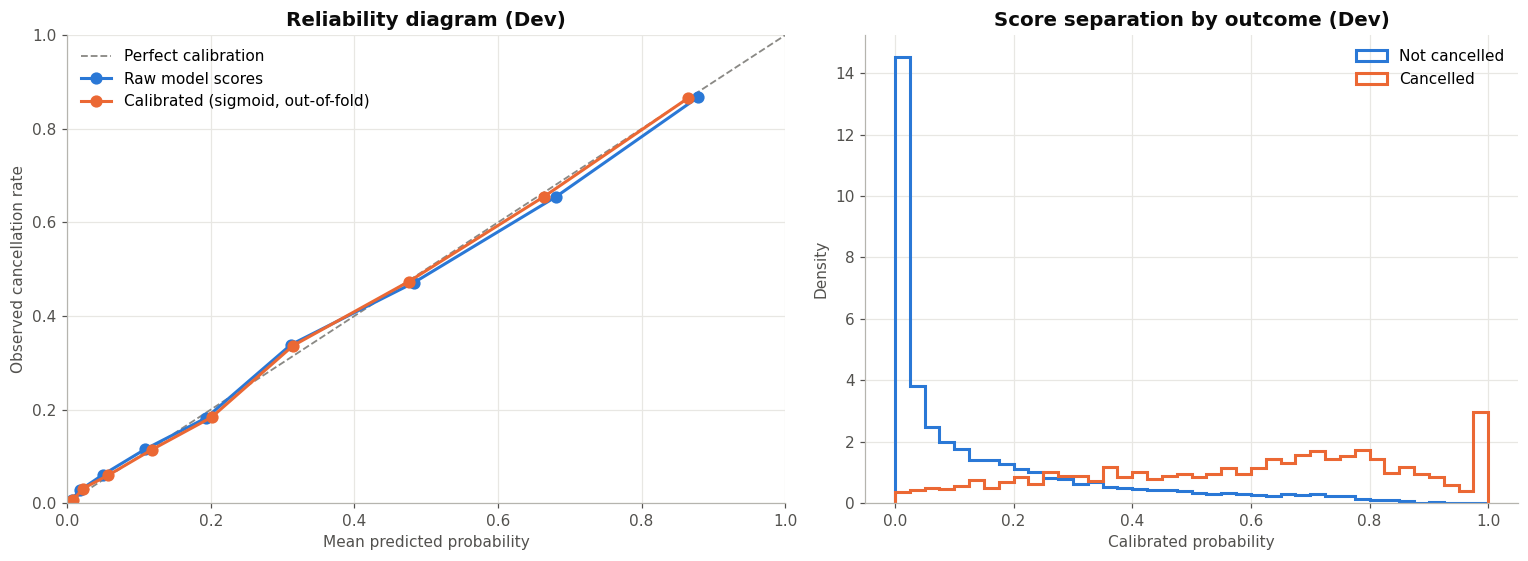

In [10]:
fig, axes = plt.subplots(1, 2, figsize=(14, 5.2), gridspec_kw={"width_ratios": [1.1, 1]})
ax = axes[0]
ax.plot([0, 1], [0, 1], color=COLORS["neutral"], linestyle="--", linewidth=1.2, label="Perfect calibration")
for color, (label, probs) in zip(SERIES_COLORS, [("Raw model scores", p_raw), (f"Calibrated ({CALIBRATION_METHOD}, out-of-fold)", oof[CALIBRATION_METHOD])]):
    frac_pos, mean_pred = calibration_curve(y_dev, probs, n_bins=CALIBRATION_BINS, strategy="quantile")
    ax.plot(mean_pred, frac_pos, marker="o", markersize=7, color=color, label=label)
ax.set(xlabel="Mean predicted probability", ylabel="Observed cancellation rate", xlim=(0, 1), ylim=(0, 1),
       title="Reliability diagram (Dev)")
ax.legend(loc="upper left")

ax = axes[1]
bins = np.linspace(0, 1, 41)
for label_value, name in [(0, "not_canceled"), (1, "canceled")]:
    ax.hist(oof[CALIBRATION_METHOD][y_dev == label_value], bins=bins, histtype="step", linewidth=2, density=True,
            color=COLORS[name], label="Cancelled" if label_value else "Not cancelled")
ax.set(xlabel="Calibrated probability", ylabel="Density", title="Score separation by outcome (Dev)")
ax.legend()
fig.tight_layout()
save_figure(fig, "calibration")
plt.show()

## 4. Threshold analysis
### 4.1 Booking value for the cost model (from Train)
The typical booking value is the median of `adr × total_nights` over paid stays in
**Train**. It is a business constant derived from the data the model was trained on.

In [11]:
train_features = read_frame(PATHS["features"] / "train.csv")
booking_value = train_features["adr"] * train_features["total_nights"]
MEDIAN_BOOKING_VALUE = float(booking_value[booking_value > 0].median())

COSTS = {
    "fn": COST_ASSUMPTIONS["loss_if_unmanaged"] * MEDIAN_BOOKING_VALUE,
    "tp": COST_ASSUMPTIONS["follow_up_cost"] + COST_ASSUMPTIONS["loss_if_managed"] * MEDIAN_BOOKING_VALUE,
    "fp": COST_ASSUMPTIONS["follow_up_cost"] + COST_ASSUMPTIONS["friction_cost"],
    "tn": 0.0,
}
bayes_threshold = COSTS["fp"] / (COSTS["fn"] - COSTS["tp"] + COSTS["fp"])
print(f"Median booking value (Train): {MEDIAN_BOOKING_VALUE:.2f}")
print("Per-outcome costs:", {k: round(v, 2) for k, v in COSTS.items()})
print(f"Theoretical cost-optimal threshold for perfectly calibrated scores: {bayes_threshold:.3f}")

Median booking value (Train): 303.00
Per-outcome costs: {'fn': 90.9, 'tp': 45.3, 'fp': 25.0, 'tn': 0.0}
Theoretical cost-optimal threshold for perfectly calibrated scores: 0.354


### 4.2 Threshold sweep on out-of-fold calibrated Dev scores
For every candidate threshold: precision, recall, F1, the share of bookings flagged,
and expected cost per 1,000 bookings. "No model" = never flag (all cancellations
missed). It is the cost reference.

In [12]:
p_cal = oof[CALIBRATION_METHOD]


def sweep(y, p, thresholds, costs) -> pd.DataFrame:
    rows = []
    for t in thresholds:
        pred = p >= t
        tp, fp = int((pred & (y == 1)).sum()), int((pred & (y == 0)).sum())
        fn, tn = int((~pred & (y == 1)).sum()), int((~pred & (y == 0)).sum())
        cost = tp * costs["tp"] + fp * costs["fp"] + fn * costs["fn"] + tn * costs["tn"]
        precision = tp / (tp + fp) if tp + fp else 0.0
        recall = tp / (tp + fn) if tp + fn else 0.0
        f1 = 2 * precision * recall / (precision + recall) if precision + recall else 0.0
        rows.append({"threshold": t, "precision": precision, "recall": recall, "f1": f1, "flag_rate": pred.mean(),
                     "tp": tp, "fp": fp, "fn": fn, "tn": tn, "cost_per_1000": cost / len(y) * 1000})
    return pd.DataFrame(rows)


threshold_table = sweep(y_dev, p_cal, THRESHOLD_GRID, COSTS)
no_model_cost = y_dev.sum() * COSTS["fn"] / len(y_dev) * 1000
cost_optimal = threshold_table.loc[threshold_table["cost_per_1000"].idxmin()]
f1_optimal = threshold_table.loc[threshold_table["f1"].idxmax()]
threshold_table.to_csv(PATHS["tables"] / "12_threshold_sweep_dev.csv", index=False)

print(f"Cost-optimal threshold: {cost_optimal['threshold']:.2f} -> cost/1000 {cost_optimal['cost_per_1000']:.0f} "
      f"(no model: {no_model_cost:.0f}; saving {1 - cost_optimal['cost_per_1000'] / no_model_cost:.1%})")
print(f"F1-optimal threshold:   {f1_optimal['threshold']:.2f} (F1 {f1_optimal['f1']:.3f})")
threshold_table[threshold_table["threshold"].isin([0.2, 0.3, 0.4, 0.5, 0.6, 0.7])].round(3)

Cost-optimal threshold: 0.35 -> cost/1000 18079 (no model: 24792; saving 27.1%)
F1-optimal threshold:   0.35 (F1 0.703)


,threshold,precision,recall,f1,flag_rate,tp,fp,fn,tn,cost_per_1000
15,0.2,0.542,0.894,0.675,0.450,3188,2698,377,6808,18830.671
25,0.3,0.615,0.810,0.699,0.359,2886,1810,679,7696,18185.824
35,0.4,0.673,0.719,0.695,0.292,2563,1248,1002,8258,18237.755
45,0.5,0.727,0.628,0.674,0.236,2240,841,1325,8665,18586.145
55,0.6,0.777,0.531,0.631,0.186,1892,542,1673,8964,19228.315
65,0.7,0.826,0.394,0.534,0.130,1405,295,2160,9211,20454.862


### 4.3 Precision / recall / F1 and expected cost vs threshold
Two panels, each with a single y-scale: rates on the left, cost on the right.

**How to run:** to refresh this chart, run sections 1 to 5 only. Section 6 rewrites the
locked policy and the final model used by notebook 14.

Saved figure -> reports/figures/12_threshold_analysis.png


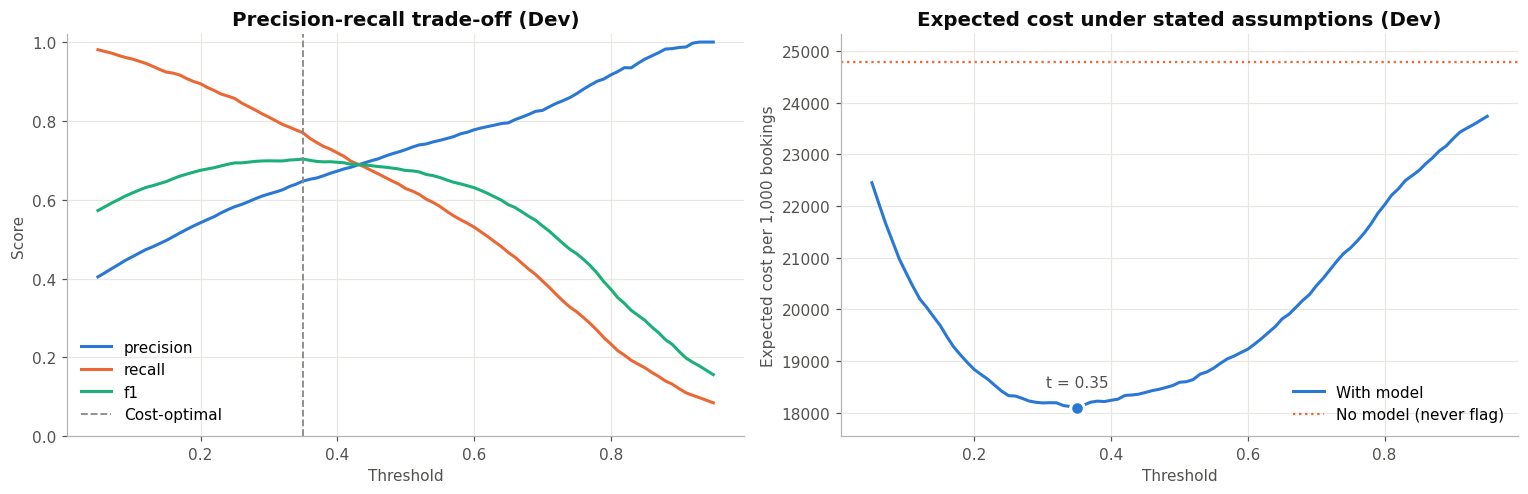

In [13]:
fig, axes = plt.subplots(1, 2, figsize=(14, 4.6))
ax = axes[0]
for color, metric in zip(SERIES_COLORS, ["precision", "recall", "f1"]):
    ax.plot(threshold_table["threshold"], threshold_table[metric], color=color, label=metric)
ax.axvline(cost_optimal["threshold"], color=COLORS["neutral"], linestyle="--", linewidth=1.2, label="Cost-optimal")
ax.set(xlabel="Threshold", ylabel="Score", ylim=(0, 1.02), title="Precision-recall trade-off (Dev)")
ax.legend(loc="lower left")

ax = axes[1]
ax.plot(threshold_table["threshold"], threshold_table["cost_per_1000"], color=SERIES_COLORS[0], label="With model")
ax.axhline(no_model_cost, color=COLORS["canceled"], linestyle=":", linewidth=1.5, label="No model (never flag)")
ax.scatter([cost_optimal["threshold"]], [cost_optimal["cost_per_1000"]], s=80, color=SERIES_COLORS[0], edgecolor="white",
           linewidth=2, zorder=3)
ax.annotate(f"t = {cost_optimal['threshold']:.2f}", (cost_optimal["threshold"], cost_optimal["cost_per_1000"]),
            textcoords="offset points", xytext=(0, 14), ha="center", color=COLORS["ink_muted"])
cost_low, cost_high = threshold_table["cost_per_1000"].min(), max(threshold_table["cost_per_1000"].max(), no_model_cost)
ax.set_ylim(cost_low - 0.08 * (cost_high - cost_low), cost_high + 0.08 * (cost_high - cost_low))
ax.set(xlabel="Threshold", ylabel="Expected cost per 1,000 bookings", title="Expected cost under stated assumptions (Dev)")
ax.legend(loc="lower right")
fig.tight_layout()
save_figure(fig, "threshold_analysis")
plt.show()

### 4.4 Sensitivity: how does the optimal threshold move with the cost ratio?
The cost assumptions are uncertain, so we vary the missed-cancellation cost relative to
the false-alarm cost. A flat region means the recommendation is robust. A steep one
means the hotel must pin down its real costs before deployment.

Saved figure -> reports/figures/12_threshold_sensitivity.png


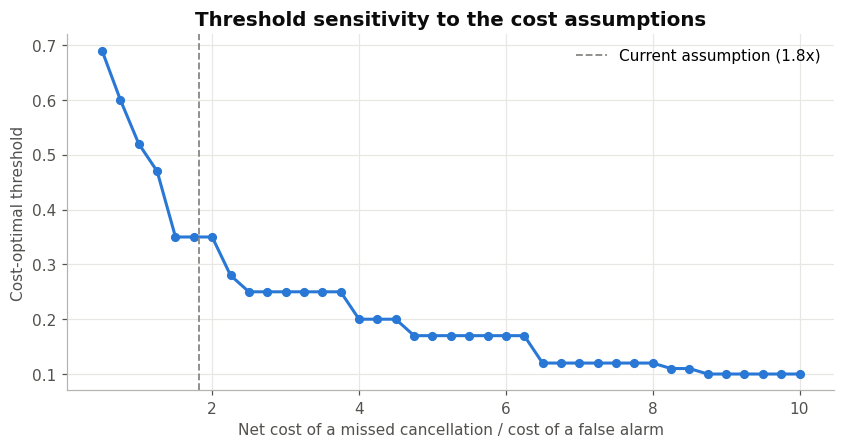

In [14]:
ratios = np.round(np.linspace(0.5, 10, 39), 2)
sensitivity = []
for ratio in ratios:
    scaled = {**COSTS, "fn": COSTS["fp"] * ratio + COSTS["tp"]}  # keep TP fixed, vary FN relative to FP
    table = sweep(y_dev, p_cal, THRESHOLD_GRID, scaled)
    best = table.loc[table["cost_per_1000"].idxmin()]
    sensitivity.append({"fn_to_fp_ratio": ratio, "optimal_threshold": best["threshold"], "recall": best["recall"],
                        "flag_rate": best["flag_rate"]})
sensitivity = pd.DataFrame(sensitivity)
current_ratio = (COSTS["fn"] - COSTS["tp"]) / COSTS["fp"]

fig, ax = plt.subplots(figsize=(9, 4.2))
ax.plot(sensitivity["fn_to_fp_ratio"], sensitivity["optimal_threshold"], color=SERIES_COLORS[0], marker="o", markersize=5)
ax.axvline(current_ratio, color=COLORS["neutral"], linestyle="--", linewidth=1.2, label=f"Current assumption ({current_ratio:.1f}x)")
ax.set(xlabel="Net cost of a missed cancellation / cost of a false alarm", ylabel="Cost-optimal threshold",
       title="Threshold sensitivity to the cost assumptions")
ax.legend()
save_figure(fig, "threshold_sensitivity")
plt.show()
sensitivity.to_csv(PATHS["tables"] / "12_threshold_sensitivity.csv", index=False)

## 5. Risk tiers (Low / Medium / High)
- **High:** score ≥ cost-optimal threshold. Act now (follow-up and revenue action).
- **Medium:** score ≥ the threshold at which Medium+High capture ≥ 90 % of cancellations.
  Monitor.
- **Low:** everything else. No action.

Each tier reports its size, its observed cancellation rate and its share of all
cancellations, which is what a reservations manager needs to plan staff time.

In [15]:
HIGH_THRESHOLD = float(cost_optimal["threshold"])
meets_recall = threshold_table[threshold_table["recall"] >= MEDIUM_TIER_TARGET_RECALL]
MEDIUM_THRESHOLD = float(meets_recall["threshold"].max()) if len(meets_recall) else float(THRESHOLD_GRID.min())
if MEDIUM_THRESHOLD >= HIGH_THRESHOLD:
    MEDIUM_THRESHOLD = round(HIGH_THRESHOLD / 2, 2)

TIER_LABELS = ["Low", "Medium", "High"]


def assign_tier(p):
    return np.where(p >= HIGH_THRESHOLD, "High", np.where(p >= MEDIUM_THRESHOLD, "Medium", "Low"))


tiers = pd.DataFrame({"tier": assign_tier(p_cal), "y": y_dev})
tier_summary = tiers.groupby("tier").agg(bookings=("y", "size"), cancellations=("y", "sum")).reindex(TIER_LABELS)
tier_summary["share_of_bookings"] = tier_summary["bookings"] / len(tiers)
tier_summary["cancellation_rate"] = tier_summary["cancellations"] / tier_summary["bookings"]
tier_summary["share_of_all_cancellations"] = tier_summary["cancellations"] / tiers["y"].sum()
tier_summary.to_csv(PATHS["tables"] / "12_risk_tiers_dev.csv")
print(f"Tier cut-offs: Medium >= {MEDIUM_THRESHOLD:.2f}, High >= {HIGH_THRESHOLD:.2f}")
tier_summary.round(3)

Tier cut-offs: Medium >= 0.18, High >= 0.35


,bookings,cancellations,share_of_bookings,cancellation_rate,share_of_all_cancellations
tier,,,,,
Low,6909,331,0.529,0.048,0.093
Medium,1923,490,0.147,0.255,0.137
High,4239,2744,0.324,0.647,0.770


### 5.1 Tier chart
Observed cancellation rate per tier (single series, ordinal blue ramp from light to dark),
annotated with each tier's share of bookings.

Saved figure -> reports/figures/12_risk_tiers.png


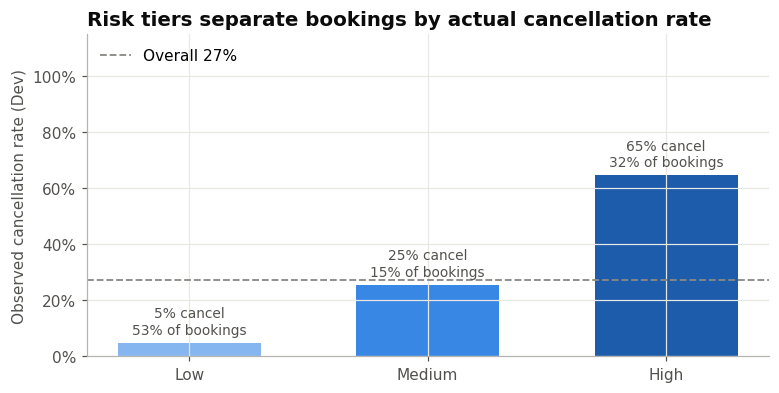

In [16]:
fig, ax = plt.subplots(figsize=(8, 3.8))
tier_colors = ["#86b6ef", "#3987e5", "#1c5cab"]
bars = ax.bar(TIER_LABELS, tier_summary["cancellation_rate"], color=tier_colors, width=0.6)
ax.bar_label(bars, labels=[f"{r:.0%} cancel\n{s:.0%} of bookings" for r, s in
                           zip(tier_summary["cancellation_rate"], tier_summary["share_of_bookings"])],
             padding=4, color=COLORS["ink_muted"], fontsize=9)
ax.axhline(y_dev.mean(), color=COLORS["neutral"], linestyle="--", linewidth=1.2, label=f"Overall {y_dev.mean():.0%}")
ax.yaxis.set_major_formatter(mpl.ticker.PercentFormatter(1.0))
ax.set_ylim(0, 1.15)
ax.set_ylabel("Observed cancellation rate (Dev)")
ax.set_title("Risk tiers separate bookings by actual cancellation rate", loc="left")
ax.legend(loc="upper left")
save_figure(fig, "risk_tiers")
plt.show()

## 6. Fit the final calibrator on all of Dev and lock the policy
The cross-fitted analysis chose the *method* and the *thresholds*. The deployed
calibrator is now refitted on all Dev rows, so it uses every available row. The policy
is hashed, and notebook 14 checks this hash before scoring Test.

In [17]:
final_calibrator = fit_calibrator(CALIBRATION_METHOD, p_raw, y_dev)
base_model = joblib.load(PROJECT_ROOT / model_card["model_path"])
bundle = {"model_id": MODEL_ID, "model": base_model, "calibration_method": CALIBRATION_METHOD,
          "calibrator": final_calibrator, "high_threshold": HIGH_THRESHOLD, "medium_threshold": MEDIUM_THRESHOLD}
bundle_path = PATHS["models"] / "final_model_calibrated.joblib"
joblib.dump(bundle, bundle_path)

policy_core = {
    "model_id": MODEL_ID,
    "model_path": model_card["model_path"],
    "model_sha256": model_card["model_sha256"],
    "bundle_path": str(bundle_path.relative_to(PROJECT_ROOT)),
    "bundle_sha256": sha256_file(bundle_path),
    "calibration_method": CALIBRATION_METHOD,
    "operating_threshold": HIGH_THRESHOLD,
    "tiers": {"Low": [0.0, MEDIUM_THRESHOLD], "Medium": [MEDIUM_THRESHOLD, HIGH_THRESHOLD], "High": [HIGH_THRESHOLD, 1.0]},
    "cost_assumptions": {**COST_ASSUMPTIONS, "median_booking_value": MEDIAN_BOOKING_VALUE, "per_outcome_costs": COSTS},
    "selected_on": "dev",
    "dev_out_of_fold": {
        "precision": float(cost_optimal["precision"]), "recall": float(cost_optimal["recall"]),
        "f1": float(cost_optimal["f1"]), "flag_rate": float(cost_optimal["flag_rate"]),
        "cost_per_1000": float(cost_optimal["cost_per_1000"]), "no_model_cost_per_1000": float(no_model_cost),
        "brier": float(calibration_table.loc[CALIBRATION_METHOD, "brier"]),
    },
}
policy_hash = hashlib.sha256(json.dumps(policy_core, sort_keys=True, default=str).encode()).hexdigest()
decision_policy = {**policy_core, "policy_sha256": policy_hash,
                   "created_at": datetime.now(timezone.utc).isoformat(timespec="seconds"),
                   "notebook": "12_calibration_threshold_policy.ipynb"}
save_json(decision_policy, PATHS["artifacts"] / "decision_policy.json")
print(f"Decision policy locked (sha256 {policy_hash[:16]}...) -> artifacts/decision_policy.json")
pd.Series({k: v for k, v in policy_core.items() if not isinstance(v, dict)}).to_frame("value")

Decision policy locked (sha256 9bd722a9865d6141...) -> artifacts/decision_policy.json


,value
model_id,xgboost__day_zero
model_path,models/xgboost__day_zero.joblib
model_sha256,3d6a71b0832cc287a6ee7a9a74719f94ab7a01176c8c7c...
bundle_path,models/final_model_calibrated.joblib
bundle_sha256,7038a470b8ccbfa2cf63e22ce21cad7a8510ea8c234b21...
calibration_method,sigmoid
operating_threshold,0.35
selected_on,dev


## 7. Notes for the report
- State the cost assumptions **as assumptions** and show the sensitivity chart (§4.4).
- Report OOF Dev precision/recall at the locked threshold. Do not report Test numbers
  until notebook 14 has run once.
- Add proposed decisions **#27** (calibration method) and **#28** (threshold and tiers) to `DECISIONS.md`.